# Notebook 9 — Aplicação do modelo aos alunos ativos

**Pergunta:** dos alunos que ainda estão cursando, quais correm risco de evadir, por quê, e o que a
instituição deve fazer a respeito?

Este notebook aplica o modelo treinado aos **794 alunos com situação `Enrolled`** — exatamente a
classe que foi removida na Fase 3 por não ter desfecho definido. É o uso pretendido do trabalho:
até aqui o modelo foi avaliado sobre trajetórias já encerradas; aqui ele opera sobre alunos que
ainda podem ser ajudados.

---

## Antes de ler os resultados: a ressalva que os condiciona

Este é o cenário da limitação **L-01**, a mais séria do trabalho, registrada em
[`docs/07`](docs/07-limitacoes-e-trabalhos-futuros.md).

| | População de **treino** | População de **aplicação** |
|---|---|---|
| Quem são | 3.630 alunos com desfecho definido | 794 alunos ativos, sem desfecho |
| O modelo aprendeu com eles? | Sim | **Não** |
| Sabemos se acertou? | Sim — F1 0,88 típico | **Não há como saber hoje** |

O modelo aprendeu a separar dois polos: quem se formou e quem evadiu. Os alunos ativos não são
nenhum dos dois — ainda. O escore que ele produz para eles responde a **"este aluno se parece com
quem evadiu?"**, e não a "qual a probabilidade de este aluno evadir".

A distinção não é preciosismo acadêmico: a Seção 3 mostra que ela tem consequência numérica direta,
e a Seção 4 mostra que ela invalida o limiar de decisão usado nas fases anteriores.

**Nenhum número deste notebook foi validado contra desfechos reais**, porque esses desfechos ainda
não existem. Os resultados servem para **priorizar atenção**, não para afirmar destino.

## 1. Carga dos artefatos e dos alunos ativos

In [1]:
import json
import sys
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import shap

warnings.filterwarnings("ignore")
sys.path.insert(0, "src")
from data_loader import ROTULOS_PT

SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

META = json.loads(Path("dados/metadados.json").read_text(encoding="utf-8"))
preprocessador = joblib.load("modelos/preprocessador.joblib")
pipeline = joblib.load("modelos/melhor_modelo.joblib")

df = pd.read_csv("dados/dataset_limpo.csv")
ativos = df[df["target"] == "Enrolled"].reset_index(drop=True)
X_bruto = ativos.drop(columns=["target"])

print(f"dataset completo      : {len(df)} alunos")
print(f"alunos ativos         : {len(ativos)}  ({len(ativos)/len(df):.1%} do total)")
print(f"variáveis brutas      : {X_bruto.shape[1]}")

dataset completo      : 4424 alunos
alunos ativos         : 794  (17.9% do total)
variáveis brutas      : 36


C:\Codigos_Git\Pessoal\tcc-dropout-prediction\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Os alunos ativos nunca passaram pelo modelo: foram removidos no Notebook 2, antes do treino. Não há
risco de vazamento aqui — o modelo não os viu em nenhum momento.

## 2. Aplicação do pré-processamento e do modelo

In [2]:
X = pd.DataFrame(preprocessador.transform(X_bruto),
                 columns=preprocessador.get_feature_names_out())
assert X.shape[1] == META["n_features"], "número de features divergente"

escore = pipeline.predict_proba(X)[:, 1]

print(f"features geradas      : {X.shape[1]}")
print(f"escores calculados    : {len(escore)}")
print()
print(f"  mínimo   : {escore.min():.4f}")
print(f"  mediana  : {np.median(escore):.4f}")
print(f"  média    : {escore.mean():.4f}")
print(f"  máximo   : {escore.max():.4f}")

features geradas      : 105
escores calculados    : 794

  mínimo   : 0.0063
  mediana  : 0.4800
  média    : 0.5098
  máximo   : 0.9995


O pré-processador foi **apenas aplicado**, nunca reajustado: usa a média e o desvio aprendidos no
treino. Reajustá-lo aqui seria um erro sutil — os alunos ativos passariam a ser padronizados pela
própria distribuição, e deixariam de ser comparáveis à população que o modelo aprendeu.

## 3. O achado central: os alunos ativos vivem na zona de indecisão

Antes de olhar quem está em risco, é preciso olhar **onde** os alunos ativos caem na escala do modelo.

In [3]:
concluidos = df[df["target"].isin(["Dropout", "Graduate"])].reset_index(drop=True)
X_conc = pd.DataFrame(preprocessador.transform(concluidos.drop(columns=["target"])),
                      columns=preprocessador.get_feature_names_out())
escore_conc = pipeline.predict_proba(X_conc)[:, 1]

grupos = {
    "Dropout (evadiram)":  escore_conc[concluidos["target"] == "Dropout"],
    "Enrolled (ativos)":   escore,
    "Graduate (formaram)": escore_conc[concluidos["target"] == "Graduate"],
}

print("=== distribuição do escore por situação ===")
print(f"{'grupo':<22} {'n':>5} {'mediana':>9} {'% na zona 0,2–0,8':>20}")
for nome, v in grupos.items():
    zona = ((v >= 0.2) & (v <= 0.8)).mean()
    print(f"{nome:<22} {len(v):>5} {np.median(v):>9.3f} {zona:>19.1%}")

=== distribuição do escore por situação ===
grupo                      n   mediana    % na zona 0,2–0,8
Dropout (evadiram)      1421     0.984               17.5%
Enrolled (ativos)        794     0.480               42.4%
Graduate (formaram)     2209     0.058               13.1%


**Este é o resultado mais importante do notebook.**

Os alunos concluídos ficam nos extremos — quem evadiu perto de 1, quem se formou perto de 0. Os
alunos ativos ficam **no meio**, com mediana próxima de 0,5 e uma fração muito maior dentro da zona
de indecisão.

Não é defeito do modelo: é a consequência direta de ele nunca ter visto essa população. Os escores
dos concluídos são, além disso, otimistas — parte desses alunos esteve no treino, então o modelo já
os conhece. A separação real seria menor. A comparação continua válida para o que importa aqui: os
ativos estão sistematicamente mais próximos da fronteira do que qualquer grupo que o modelo aprendeu.

**Consequência prática:** o escore ordena bem, mas não deve ser lido como probabilidade para esta
população.

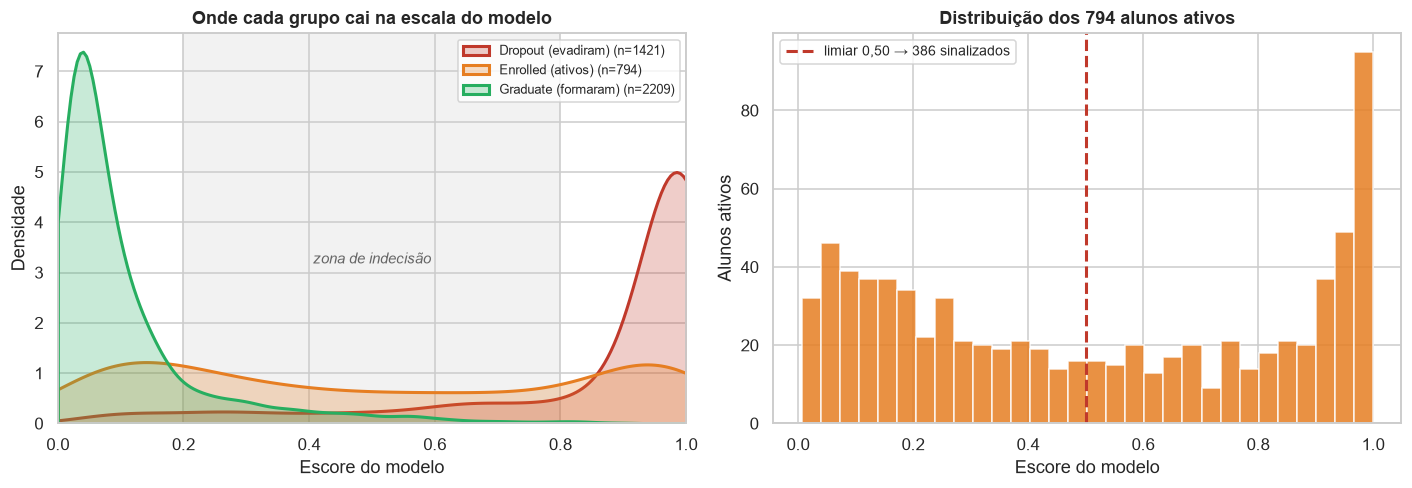

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))

cores = {"Dropout (evadiram)": "#c0392b", "Enrolled (ativos)": "#e67e22",
         "Graduate (formaram)": "#27ae60"}
for nome, v in grupos.items():
    sns.kdeplot(v, ax=axes[0], label=f"{nome} (n={len(v)})",
                fill=True, alpha=0.25, linewidth=2, color=cores[nome], clip=(0, 1))
axes[0].axvspan(0.2, 0.8, color="grey", alpha=0.10, zorder=0)
axes[0].text(0.5, axes[0].get_ylim()[1] * 0.42, "zona de indecisão",
             ha="center", va="center", fontsize=9.5, color="#666", style="italic")
axes[0].set_xlabel("Escore do modelo")
axes[0].set_ylabel("Densidade")
axes[0].set_title("Onde cada grupo cai na escala do modelo", fontweight="bold")
axes[0].legend(fontsize=8.5, loc="upper right")
axes[0].set_xlim(0, 1)

axes[1].hist(escore, bins=30, color="#e67e22", edgecolor="white", alpha=0.85)
axes[1].axvline(0.50, color="#c0392b", ls="--", lw=2,
                label=f"limiar 0,50 → {(escore>=0.50).sum()} sinalizados")
axes[1].set_xlabel("Escore do modelo")
axes[1].set_ylabel("Alunos ativos")
axes[1].set_title(f"Distribuição dos {len(escore)} alunos ativos", fontweight="bold")
axes[1].legend(fontsize=9)

plt.tight_layout()
plt.savefig("figuras/26_alunos_ativos_distribuicao.png", dpi=200, bbox_inches="tight")
plt.show()

## 4. Por que o limiar 0,50 não pode ser transplantado

O limiar de 0,50 foi avaliado sobre a população de trajetórias concluídas. Aplicado aqui, produz um
resultado operacionalmente inviável.

In [5]:
print(f"{'limiar':>7} {'sinalizados':>12} {'% dos ativos':>14}")
for lim in (0.30, 0.40, 0.50, 0.60, 0.70, 0.80, 0.90):
    n = int((escore >= lim).sum())
    print(f"{lim:>7.2f} {n:>12} {n/len(escore):>13.1%}")

 limiar  sinalizados   % dos ativos
   0.30          494         62.2%
   0.40          436         54.9%
   0.50          386         48.6%
   0.60          336         42.3%
   0.70          286         36.0%
   0.80          240         30.2%
   0.90          181         22.8%


Sinalizar quase metade dos alunos ativos não é uma política de intervenção — é uma lista que nenhuma
coordenação consegue atender, e que por isso não seria atendida.

Este ponto reforça, com dados novos, o que o Notebook 3 (§9) já havia estabelecido: **o limiar é
decisão institucional, não propriedade do modelo.** Ele deve sair da capacidade real de atendimento.

### A alternativa: partir da capacidade, não do limiar

Em vez de perguntar "quem passa de 0,50?", pergunte "quantos alunos conseguimos atender?" e convoque
os N de maior escore. O modelo ordena; a instituição define o corte.

In [6]:
print(f"{'capacidade':>11} {'escore de corte':>17} {'menor escore convocado':>24}")
for n in (25, 50, 100, 150, 200):
    corte = np.sort(escore)[-n]
    print(f"{n:>11} {corte:>17.3f} {corte:>24.3f}")

 capacidade   escore de corte   menor escore convocado
         25             0.994                    0.994
         50             0.988                    0.988
        100             0.966                    0.966
        150             0.929                    0.929
        200             0.870                    0.870


Ler assim inverte a pergunta de forma útil: com 50 vagas de monitoria, o corte natural é o escore do
50º aluno. Nenhum limiar precisa ser justificado teoricamente — ele decorre do orçamento.

## 5. Por que cada aluno está em risco — SHAP em lote

O escore diz **quem**. Sozinho, ele não permite agir. O SHAP decompõe cada predição individual nas
variáveis que a produziram, o que transforma a lista em encaminhamento.

In [7]:
modelo = pipeline.named_steps[list(pipeline.named_steps)[-1]]
explainer = shap.TreeExplainer(modelo)
shap_vals = explainer.shap_values(X)

# Aditividade: valor base + soma das contribuições = margem bruta do modelo.
# A comparação é feita contra `output_margin=True`, que é a grandeza que o
# TreeSHAP explica. Compará-la contra o logit recalculado da probabilidade daria
# um erro artificialmente maior: escores próximos de 1 amplificam o arredondamento
# de float32 na reconversão.
margem_modelo = modelo.predict(X, output_margin=True)
margem_shap = shap_vals.sum(axis=1) + explainer.expected_value

erro = float(np.abs(margem_shap - margem_modelo).max())
print(f"valores SHAP        : {shap_vals.shape}")
print(f"erro de aditividade : {erro:.2e}  (mesma ordem do Notebook 4)")
assert erro < 1e-4, "aditividade violada — não prosseguir com a interpretação"

valores SHAP        : (794, 105)
erro de aditividade : 3.34e-06  (mesma ordem do Notebook 4)


In [8]:
ENCAMINHAMENTO = {
    "tuition_fees_up_to_date": ("Financeiro", "Renegociação de mensalidade"),
    "debtor": ("Financeiro", "Renegociação de mensalidade"),
    "scholarship_holder": ("Financeiro", "Avaliar concessão de bolsa"),
    "curricular_units_1st_sem_approved": ("Pedagógico", "Monitoria ou tutoria"),
    "curricular_units_2nd_sem_approved": ("Pedagógico", "Monitoria ou tutoria"),
    "curricular_units_1st_sem_grade": ("Pedagógico", "Monitoria ou tutoria"),
    "curricular_units_2nd_sem_grade": ("Pedagógico", "Monitoria ou tutoria"),
    "curricular_units_1st_sem_enrolled": ("Acadêmico", "Revisar carga de disciplinas"),
    "curricular_units_2nd_sem_enrolled": ("Acadêmico", "Revisar carga de disciplinas"),
    "curricular_units_1st_sem_evaluations": ("Contato", "Possível abandono em curso"),
    "curricular_units_2nd_sem_evaluations": ("Contato", "Possível abandono em curso"),
    "age_at_enrollment": ("Acadêmico", "Flexibilização de carga e prazos"),
    "daytime_evening_attendance": ("Acadêmico", "Flexibilização de carga e prazos"),
}


def variavel_de_origem(feature):
    for base in sorted(META["cols_nominais"], key=len, reverse=True):
        if feature == base or feature.startswith(base + "_"):
            return base
    return feature


def rotulo(feature):
    if feature in ROTULOS_PT:
        return ROTULOS_PT[feature]
    base = variavel_de_origem(feature)
    if base != feature and base in ROTULOS_PT:
        return f"{ROTULOS_PT[base]} {feature[len(base) + 1:]}"
    return feature


def formatar(valor):
    if isinstance(valor, (int, np.integer)) or float(valor).is_integer():
        return str(int(valor))
    return f"{float(valor):.2f}"


print("dicionário de encaminhamento:", len(ENCAMINHAMENTO), "variáveis mapeadas")

dicionário de encaminhamento: 13 variáveis mapeadas


In [9]:
registros = []
for i in range(len(X)):
    contrib = shap_vals[i]
    ordem = np.argsort(-contrib)          # maiores empurrões PARA evasão
    fatores, areas = [], []
    for j in ordem[:3]:
        if contrib[j] <= 0:
            continue
        feat = X.columns[j]
        base = variavel_de_origem(feat)
        # Numa dummy o rótulo já contém a categoria ("Curso 9119"); repetir o
        # valor bruto ao lado seria redundante. Só variáveis diretas levam valor.
        if feat == base and base in X_bruto.columns:
            fatores.append(f"{rotulo(feat)} = {formatar(X_bruto.iloc[i][base])}")
        else:
            fatores.append(rotulo(feat))
        if base in ENCAMINHAMENTO:
            areas.append(ENCAMINHAMENTO[base])

    principal = areas[0] if areas else ("Individual", "Análise caso a caso")
    outras = [a for a in areas[1:] if a[0] != principal[0]]

    registros.append({
        "escore": round(float(escore[i]), 4),
        "faixa": ("Muito alto" if escore[i] >= 0.90 else
                  "Alto" if escore[i] >= 0.70 else
                  "Moderado" if escore[i] >= 0.40 else "Baixo"),
        "fator_1": fatores[0] if fatores else "—",
        "fator_2": fatores[1] if len(fatores) > 1 else "—",
        "fator_3": fatores[2] if len(fatores) > 2 else "—",
        "area": principal[0],
        "acao": principal[1],
        "area_secundaria": outras[0][0] if outras else "—",
    })

lista = pd.DataFrame(registros)
lista.insert(0, "aluno", ativos.index)
lista = lista.sort_values("escore", ascending=False).reset_index(drop=True)
lista.insert(0, "prioridade", range(1, len(lista) + 1))

print(f"lista construída: {len(lista)} alunos")

lista construída: 794 alunos


## 6. A lista priorizada

In [10]:
pd.set_option("display.width", 190)
pd.set_option("display.max_colwidth", 40)

print("=== 15 alunos de maior risco ===")
print(lista.head(15)[["prioridade", "aluno", "escore", "faixa",
                      "fator_1", "fator_2", "area"]].to_string(index=False))

=== 15 alunos de maior risco ===
 prioridade  aluno  escore      faixa                             fator_1                                fator_2       area
          1    156  0.9995 Muito alto Disciplinas aprovadas (2º sem.) = 0                Mensalidades em dia = 0 Pedagógico
          2    553  0.9994 Muito alto Disciplinas aprovadas (2º sem.) = 0                Mensalidades em dia = 0 Pedagógico
          3    390  0.9992 Muito alto Disciplinas aprovadas (2º sem.) = 0                Mensalidades em dia = 0 Pedagógico
          4    267  0.9990 Muito alto Disciplinas aprovadas (2º sem.) = 2                Mensalidades em dia = 0 Pedagógico
          5     29  0.9988 Muito alto Disciplinas aprovadas (2º sem.) = 0                Mensalidades em dia = 0 Pedagógico
          6    403  0.9987 Muito alto Disciplinas aprovadas (2º sem.) = 1 Disciplinas matriculadas (1º sem.) = 7 Pedagógico
          7    414  0.9981 Muito alto Disciplinas aprovadas (2º sem.) = 1                          

In [11]:
print("=== distribuição por faixa de risco ===")
faixas = lista["faixa"].value_counts().reindex(["Muito alto", "Alto", "Moderado", "Baixo"])
for nome, n in faixas.items():
    print(f"  {nome:<12} {n:>4} alunos  ({n/len(lista):>5.1%})")

print()
print("=== área de encaminhamento — todos os ativos ===")
print(lista["area"].value_counts().to_string())

print()
print("=== área de encaminhamento — 100 de maior risco ===")
print(lista.head(100)["area"].value_counts().to_string())

print()
print("=== alunos com fatores de risco em MAIS DE UMA área ===")
duplo = lista[lista["area_secundaria"] != "—"]
print(f"  {len(duplo)} de {len(lista)} ({len(duplo)/len(lista):.1%}) — exigem ação coordenada")
print()
print("  combinações mais frequentes:")
combo = (duplo.groupby(["area", "area_secundaria"]).size()
         .sort_values(ascending=False).head(5))
for (a, b), n in combo.items():
    print(f"    {a} + {b:<12} {n:>4}")

=== distribuição por faixa de risco ===
  Muito alto    181 alunos  (22.8%)
  Alto          105 alunos  (13.2%)
  Moderado      150 alunos  (18.9%)
  Baixo         358 alunos  (45.1%)

=== área de encaminhamento — todos os ativos ===
area
Pedagógico    451
Acadêmico     190
Financeiro     75
Contato        43
Individual     35

=== área de encaminhamento — 100 de maior risco ===
area
Pedagógico    95
Financeiro     5

=== alunos com fatores de risco em MAIS DE UMA área ===
  442 de 794 (55.7%) — exigem ação coordenada

  combinações mais frequentes:
    Pedagógico + Acadêmico     142
    Pedagógico + Contato        70
    Pedagógico + Financeiro     64
    Acadêmico + Contato        56
    Financeiro + Acadêmico      26


A composição muda com a severidade, e isso tem leitura direta: entre os alunos de maior risco o
encaminhamento é quase todo pedagógico, enquanto o bloco financeiro aparece mais distribuído ao longo
da lista. Faz sentido — parar de aprovar disciplinas é o sinal mais tardio e mais forte; a
inadimplência aparece antes e nem sempre leva à evasão.

Os alunos cujos três fatores principais atravessam **mais de uma área** são os que mais escapam de
fluxos institucionais comuns, porque cada setor tende a tratá-los como caso do outro. Aqui eles têm
nome e ordem de prioridade.

> **Como ler a coluna `area`.** Ela vem do fator de maior contribuição SHAP, o que implementa a
> recomendação R-5 do Notebook 4. Não é um diagnóstico: é o encaminhamento de entrada. A coluna
> `area_secundaria` existe justamente porque o fator dominante não esgota o caso.

## 7. Um caso individual, em detalhe

In [12]:
alvo = int(lista.iloc[0]["aluno"])
pos = list(ativos.index).index(alvo)

print(f"=== aluno {alvo} — prioridade 1 ===")
print(f"escore: {escore[pos]:.4f}")
print()
print("dados brutos relevantes:")
for c in ["curricular_units_1st_sem_approved", "curricular_units_2nd_sem_approved",
          "curricular_units_1st_sem_grade", "curricular_units_2nd_sem_grade",
          "tuition_fees_up_to_date", "debtor", "scholarship_holder", "age_at_enrollment"]:
    print(f"  {ROTULOS_PT.get(c, c):<36} {formatar(X_bruto.iloc[pos][c])}")

print()
print("decomposição SHAP (5 maiores contribuições):")
contrib = shap_vals[pos]
for j in np.argsort(-np.abs(contrib))[:5]:
    sinal = "aumenta o risco" if contrib[j] > 0 else "reduz o risco"
    print(f"  {rotulo(X.columns[j]):<36} {contrib[j]:>+7.3f}   {sinal}")

=== aluno 156 — prioridade 1 ===
escore: 0.9995

dados brutos relevantes:
  Disciplinas aprovadas (1º sem.)      0
  Disciplinas aprovadas (2º sem.)      0
  Média das notas (1º sem.)            0
  Média das notas (2º sem.)            0
  Mensalidades em dia                  0
  Inadimplente                         1
  Bolsista                             0
  Idade no ingresso                    18

decomposição SHAP (5 maiores contribuições):
  Disciplinas aprovadas (2º sem.)       +2.368   aumenta o risco
  Mensalidades em dia                   +1.697   aumenta o risco
  Curso 9119                            +0.968   aumenta o risco
  Disciplinas aprovadas (1º sem.)       +0.855   aumenta o risco
  Inadimplente                          +0.848   aumenta o risco


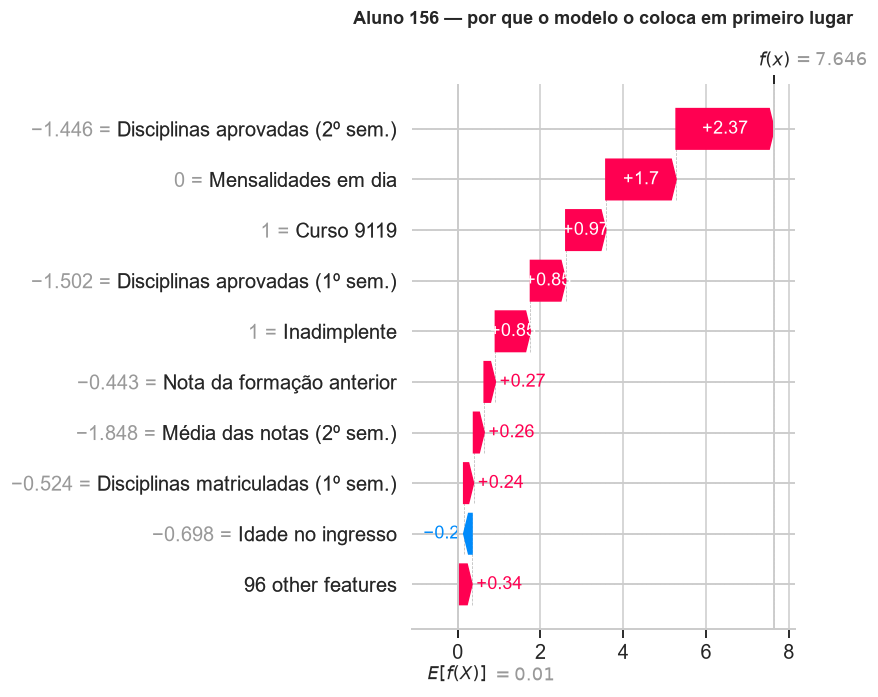

In [13]:
shap.plots.waterfall(
    shap.Explanation(values=shap_vals[pos],
                     base_values=explainer.expected_value,
                     data=X.iloc[pos].values,
                     feature_names=[rotulo(c) for c in X.columns]),
    max_display=10, show=False)
plt.title(f"Aluno {alvo} — por que o modelo o coloca em primeiro lugar", fontweight="bold", pad=18)
plt.tight_layout()
plt.savefig("figuras/27_aluno_ativo_waterfall.png", dpi=200, bbox_inches="tight")
plt.show()

> **Como ler os números à esquerda das barras.** São os valores **padronizados** (subtraída a média do
> treino, dividido pelo desvio), não os valores originais — mesma convenção da figura 18 do Notebook 4.
> Por isso "−1,446 = Disciplinas aprovadas (2º sem.)" aparece onde o valor real é **zero**: o aluno está
> 1,45 desvios abaixo da média. Os valores originais estão na saída da célula anterior.

A barra vermelha grande no topo é o núcleo do caso: **zero disciplinas aprovadas no 2º semestre**,
sozinha empurrando +2,37 em log-odds. Somada à inadimplência e às mensalidades atrasadas, produz o
maior escore dos 794.

Este aluno tem 18 anos, entrou há pouco e já não aprovou nada em dois semestres — é o perfil que a
literatura chama de abandono precoce, e é acionável: ninguém precisa esperar o desfecho para agir.

## 8. Exportação para uso institucional

In [14]:
saida = lista.copy()
saida["escore"] = saida["escore"].round(4)
saida = saida[["prioridade", "aluno", "escore", "faixa", "area", "acao",
               "area_secundaria", "fator_1", "fator_2", "fator_3"]]
saida.to_csv("dados/alunos_ativos_priorizados.csv", index=False, encoding="utf-8-sig")

print(f"[salvo] dados/alunos_ativos_priorizados.csv  ({len(saida)} linhas)")
print()
print("colunas:", ", ".join(saida.columns))
print()
print("O arquivo abre no Excel com acentuação correta (utf-8-sig).")

[salvo] dados/alunos_ativos_priorizados.csv  (794 linhas)

colunas: prioridade, aluno, escore, faixa, area, acao, area_secundaria, fator_1, fator_2, fator_3

O arquivo abre no Excel com acentuação correta (utf-8-sig).


A coluna `aluno` é o índice da linha no `dataset_limpo.csv`. Num sistema real seria a matrícula — o
dataset do UCI é anonimizado e não a contém.

## 9. Síntese

**O que este notebook entrega**

Uma lista dos 794 alunos ativos, ordenada por risco, com os três fatores que mais pesaram em cada
caso e o setor responsável pelo encaminhamento. É o produto que a coordenação usaria.

**O que ele não entrega, e não pode**

Probabilidade validada de evasão para esta população. O modelo nunca viu alunos ativos, e os
desfechos deles ainda não existem — não há como medir acerto hoje. A Seção 3 mostra que essa não é
uma ressalva formal: os ativos caem majoritariamente na zona de indecisão, onde o modelo é menos
confiável por construção.

**Como usar corretamente**

| Uso | Adequado? |
|---|---|
| Ordenar alunos por prioridade de atenção | **Sim** — é para isso que serve |
| Definir quantos convocar a partir da capacidade | **Sim** — Seção 4 |
| Identificar o setor de encaminhamento | **Sim** — Seções 5 e 6 |
| Afirmar "este aluno tem 92% de chance de evadir" | **Não** — escore não calibrado nesta população |
| Aplicar o limiar 0,50 herdado das fases anteriores | **Não** — sinalizaria 48,6% dos ativos |
| Tomar decisão automática sem revisão humana | **Não** — nenhum desfecho foi verificado |

**Como validar de verdade**

Registre a lista hoje e confira daqui a dois semestres quem de fato evadiu. Isso converte os 794
alunos em conjunto de teste real e transforma a limitação L-01 em resultado mensurado — é o caminho
descrito em [TF-01](docs/07-limitacoes-e-trabalhos-futuros.md).